## Parallel node execution
### Goals
- This module will build on human-in-the-loop as well as the memory concepts discussed in module 2.
- We will dive into multi-agent workflows and build up to a multi-agent research assistant that ties together all of the modules from this course.
- To build this multi-agent research assistant, we'll first discuss a few LangGraph controllability topics.

We'll start with parallelization


## Fan out and Fan in

Let's build graph that over-writes the state at each step

In [2]:
from IPython.display import Image, display
from typing import Any, List
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END


In [9]:
class State(TypedDict):
    state: List[str]

class ReturnNodeValue:
    def __init__(self, node_secret: str):
        self._value = node_secret
    
    def __call__(self, state: State) -> Any:
        print(f"Adding {self._value} to {state['state']}")
        return {"state": [self._value]}


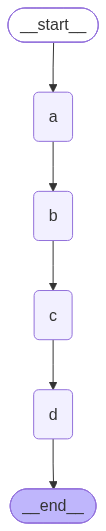

In [10]:
# Add nodes
builder = StateGraph(State)

# Initialize each node with node_secret 
builder.add_node("a", ReturnNodeValue("I'm A"))
builder.add_node("b", ReturnNodeValue("I'm B"))
builder.add_node("c", ReturnNodeValue("I'm C"))
builder.add_node("d", ReturnNodeValue("I'm D"))

# Flow
builder.add_edge(START, "a")
builder.add_edge("a", "b")
builder.add_edge("b", "c")
builder.add_edge("c", "d")
builder.add_edge("d", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
graph.invoke({"state": []})

Adding I'm A to []
Adding I'm B to ["I'm A"]
Adding I'm C to ["I'm B"]
Adding I'm D to ["I'm C"]


{'state': ["I'm D"]}